# Exploratory Data Analysis (EDA)

## Анализ данных термогравиметрии гидрогелей

В данной работе проводится разведочный анализ данных термогравиметрического анализа (ТГА) гидрогелей на основе карбоксиметил-агара и желатина при различных значениях pH.

**Цель работы** — оценить структуру и качество экспериментального датасета ТГА, проверить согласованность условий измерений, выявить особенности, влияющие на сопоставимость термограмм, и определить необходимые преобразования перед загрузкой данных в PostgreSQL.

Дополнительно проводится сравнительный анализ кривых ТГА и ДТГ при различных значениях pH.

## 1. Загрузка данных

Для анализа используются экспериментальные данные термогравиметрического анализа гидрогелей на основе карбоксиметилагара и желатина.

Исходный CSV-файл загружается из Google Drive с помощью `data_loader.py`, после чего преобразуется в формат Parquet.

Файл `data.parquet` не хранится в репозитории. Для повторного выполнения анализа его необходимо предварительно создать командой `python data_loader.py` из корневой папки проекта.

Загрузим подготовленный датасет и посмотрим на первые 10 строк.

In [ ]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


DATA_PATH = Path("data.parquet")

if not DATA_PATH.exists():
    DATA_PATH = Path("..") / "data.parquet"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Файл data.parquet не найден. Сначала запустите data_loader.py"
    )

df = pd.read_parquet(DATA_PATH)


df[
    ["sample_id", "ph", "temperature_C", "time_min",
     "mass_percent", "dtg_pct_per_min"]
].head(10)



,sample_id,ph,temperature_C,time_min,mass_percent,dtg_pct_per_min
0,pH_3.4_30_70_m2,3.4,28.255,0.00000,100.00000,-0.318620
1,pH_3.4_30_70_m2,3.4,29.255,0.32236,99.97415,-0.077649
2,pH_3.4_30_70_m2,3.4,30.255,0.64002,99.91764,-0.134300
3,pH_3.4_30_70_m2,3.4,31.255,0.82179,99.90891,0.001488
4,pH_3.4_30_70_m2,3.4,32.255,0.95176,99.92031,-0.043305
5,pH_3.4_30_70_m2,3.4,33.255,1.05976,99.90988,-0.160090
6,pH_3.4_30_70_m2,3.4,34.255,1.15582,99.88256,-0.219660
7,pH_3.4_30_70_m2,3.4,35.255,1.24444,99.85663,-0.195390
8,pH_3.4_30_70_m2,3.4,36.255,1.32823,99.84163,-0.129190
9,pH_3.4_30_70_m2,3.4,37.255,1.40898,99.83749,-0.075008


## 2. Структура датасета

Проверим количество строк и столбцов, типы данных и общую информацию о датасете.

In [2]:
print("Размер датасета:", df.shape)
print("\nТипы данных:")
print(df.dtypes)

Размер датасета: (9768, 18)

Типы данных:
temperature_C                       float64
time_min                            float64
mass_percent                        float64
gas_flow_purge2_mlmin               float64
gas_flow_protective_mlmin           float64
dtg_pct_per_min                     float64
sample_id                               str
identity_raw                            str
ph                                  float64
agar_pct                              int64
gelatin_pct                           int64
measurement_number                    int64
sample_mass_mg                      float64
heating_rate_K_min                  float64
instrument                         category
crucible_type                      category
experiment_datetime          datetime64[us]
source_file                             str
dtype: object


**Вывод:** Датасет содержит 9 768 строк и 18 столбцов. В нём представлены числовые экспериментальные данные, сведения об условиях измерений и идентификаторы образцов.

Температура, относительная масса и ДТГ представлены числовыми значениями. Дата эксперимента преобразована в формат `datetime`, а признаки `instrument` и `crucible_type` — в категориальный тип.

Текущие типы данных подходят для дальнейшего анализа, поэтому дополнительных преобразований на этом этапе не требуется.

## 3. Проверка полноты и дубликатов

Проверим наличие пропущенных значений и полностью совпадающих строк. Пропуски могут затруднять дальнейшую обработку данных, а дубликаты — приводить к повторному учёту одних и тех же измерений.

In [3]:
print("Пропущенные значения:")
print(df.isnull().sum())

print("\nКоличество дубликатов:", df.duplicated().sum())

Пропущенные значения:
temperature_C                0
time_min                     0
mass_percent                 0
gas_flow_purge2_mlmin        0
gas_flow_protective_mlmin    0
dtg_pct_per_min              0
sample_id                    0
identity_raw                 0
ph                           0
agar_pct                     0
gelatin_pct                  0
measurement_number           0
sample_mass_mg               0
heating_rate_K_min           0
instrument                   0
crucible_type                0
experiment_datetime          0
source_file                  0
dtype: int64

Количество дубликатов: 0


**Вывод:** В датасете отсутствуют пропущенные значения и полностью совпадающие строки. Следовательно, заполнение пропусков и удаление полных дубликатов не требуются.

При этом отсутствие пропусков не гарантирует корректность экспериментальных измерений. Поэтому далее необходимо проверить состав выборки, условия проведения ТГА и возможные аномальные значения.

## 4. Образцы и повторные измерения

Проверим количество измерений при каждом значении pH и убедимся, что в датасете представлены все запланированные экспериментальные условия.

Для каждого значения pH проводились три повторных измерения гидрогелей с соотношением карбоксиметилагар : желатин 30:70.

In [ ]:
print("Количество измерений:", df["sample_id"].nunique())
print("Количество исходных файлов:", df["source_file"].nunique())

measurements = df.groupby("ph").agg(
    measurements=("sample_id", "nunique"),
    points=("temperature_C", "count")
)

measurements

Количество измерений: 12
Количество исходных файлов: 12


,measurements,points
ph,,
3.4,3,2617
3.6,3,1917
3.8,3,2618
4.0,3,2616


**Вывод:** Датасет содержит 12 измерений, полученных при четырёх значениях pH: 3,4; 3,6; 3,8 и 4,0. Для каждого значения pH представлены три повторных измерения. Все запланированные экспериментальные группы присутствуют.

Количество зарегистрированных точек различается между измерениями. Причину этих различий рассмотрим в следующем разделе при проверке температурного диапазона и шага регистрации.

## 5. Температурный диапазон и шаг измерений

Проверим температурный диапазон каждого измерения и шаг между соседними зарегистрированными точками.

Эти параметры важны для дальнейшего сравнения термограмм: различия в количестве точек могут быть связаны с настройками регистрации, а не с потерей данных.

In [5]:
temperature_range = df.groupby("sample_id")["temperature_C"].agg(["min", "max", "count"])

temperature_range

,min,max,count
sample_id,,,
pH_3.4_30_70_m1,27.065,899.065,873
pH_3.4_30_70_m2,28.255,899.255,872
pH_3.4_30_70_m3,28.314,899.314,872
pH_3.6_30_70_m1,27.668,897.668,175
pH_3.6_30_70_m2,29.179,899.179,871
pH_3.6_30_70_m3,29.277,899.277,871
pH_3.8_30_70_m1,27.044,899.044,873
pH_3.8_30_70_m2,27.929,898.929,872
pH_3.8_30_70_m3,27.470,899.470,873


### Шаг регистрации температуры

Рассчитаем разность температур между соседними точками внутри каждого измерения. Для корректного расчёта предварительно упорядочим строки по идентификатору измерения и температуре.

In [ ]:
sorted_df = df.sort_values(["sample_id", "temperature_C"]).copy()

sorted_df["temperature_step"] = sorted_df.groupby(
    "sample_id"
)["temperature_C"].diff()

temperature_steps = sorted_df.groupby("sample_id")[
    "temperature_step"
].median()

temperature_steps

sample_id
pH_3.4_30_70_m1    1.0
pH_3.4_30_70_m2    1.0
pH_3.4_30_70_m3    1.0
pH_3.6_30_70_m1    5.0
pH_3.6_30_70_m2    1.0
pH_3.6_30_70_m3    1.0
pH_3.8_30_70_m1    1.0
pH_3.8_30_70_m2    1.0
pH_3.8_30_70_m3    1.0
pH_4.0_30_70_m1    1.0
pH_4.0_30_70_m2    1.0
pH_4.0_30_70_m3    1.0
Name: temperature_step, dtype: float64

**Вывод:** Измерения охватывают сопоставимые температурные диапазоны, однако количество зарегистрированных точек различается. Для большинства измерений характерен температурный шаг около 1 °C, тогда как измерение `pH_3.6_30_70_m1` выполнено с шагом около 5 °C.

Таким образом, меньшее количество точек в этом измерении объясняется отличающимся шагом регистрации, а не обязательно потерей данных. При сравнении кривых необходимо учитывать различную плотность температурных точек. В рамках ETL исходные температурные координаты сохраняются без интерполяции.

## 6. Проверка согласованности температуры и времени

При термогравиметрическом анализе образцы нагревались с заданной скоростью. Проверим, согласуется ли изменение температуры со временем регистрации и указанной в датасете скоростью нагрева.

Для этого рассчитаем скорость нагрева по соседним точкам каждого измерения.

In [ ]:
heating_df = df.sort_values(["sample_id", "time_min"]).copy()

heating_df["delta_temp"] = heating_df.groupby(
    "sample_id"
)["temperature_C"].diff()

heating_df["delta_time"] = heating_df.groupby(
    "sample_id"
)["time_min"].diff()

heating_df["calculated_rate"] = (
    heating_df["delta_temp"] / heating_df["delta_time"]
)

heating_rates = heating_df.groupby("sample_id").agg(
    set_rate=("heating_rate_K_min", "first"),
    calculated_rate=("calculated_rate", "median")
)

heating_rates.round(2)

,set_rate,calculated_rate
sample_id,,
pH_3.4_30_70_m1,10.0,10.0
pH_3.4_30_70_m2,10.0,10.0
pH_3.4_30_70_m3,10.0,10.0
pH_3.6_30_70_m1,10.0,10.0
pH_3.6_30_70_m2,10.0,10.0
pH_3.6_30_70_m3,10.0,10.0
pH_3.8_30_70_m1,10.0,10.0
pH_3.8_30_70_m2,10.0,10.0
pH_3.8_30_70_m3,10.0,10.0


**Вывод:** Для всех 12 измерений рассчитанная медианная скорость нагрева составляет 10 °C/мин, что совпадает с заданным значением 10 К/мин. Это подтверждает согласованность температурных и временных данных с установленным режимом нагрева.

Различие температурного шага одного из измерений не сопровождается изменением скорости нагрева: при более крупном шаге регистрации увеличивается и интервал времени между точками.

Таким образом, оснований корректировать температурные или временные данные на этапе ETL не выявлено.

## 7. Проверка исходной массы навесок

Исходная масса навески является одним из параметров проведения ТГА и может влиять на условия тепло- и массопереноса.

Проверим значения массы для каждого измерения. Поскольку в датасете относительная масса уже выражена в процентах, дополнительная нормализация на исходную массу не требуется.

In [8]:
sample_masses = df.groupby(
    ["ph", "sample_id"], as_index=False
)["sample_mass_mg"].first()

sample_masses

,ph,sample_id,sample_mass_mg
0,3.4,pH_3.4_30_70_m1,5.8265
1,3.4,pH_3.4_30_70_m2,6.3694
2,3.4,pH_3.4_30_70_m3,5.9381
3,3.6,pH_3.6_30_70_m1,6.7121
4,3.6,pH_3.6_30_70_m2,6.7530
5,3.6,pH_3.6_30_70_m3,5.5050
6,3.8,pH_3.8_30_70_m1,6.6588
7,3.8,pH_3.8_30_70_m2,7.1610
8,3.8,pH_3.8_30_70_m3,6.1230
9,4.0,pH_4.0_30_70_m1,6.2189


In [9]:
df.groupby("sample_id")["sample_mass_mg"].nunique()

sample_id
pH_3.4_30_70_m1    1
pH_3.4_30_70_m2    1
pH_3.4_30_70_m3    1
pH_3.6_30_70_m1    1
pH_3.6_30_70_m2    1
pH_3.6_30_70_m3    1
pH_3.8_30_70_m1    1
pH_3.8_30_70_m2    1
pH_3.8_30_70_m3    1
pH_4.0_30_70_m1    1
pH_4.0_30_70_m2    1
pH_4.0_30_70_m3    1
Name: sample_mass_mg, dtype: int64

**Вывод:** Исходные массы навесок сохраняются в датасете как экспериментальные параметры. Поскольку термогравиметрические кривые представлены в виде относительной массы (%), дополнительная нормализация в рамках ETL не требуется.

Различия между навесками сами по себе не являются основанием для исключения измерений. При последующей интерпретации термограмм необходимо учитывать, что исходная масса может влиять на условия проведения анализа.

Проверка также показала, что внутри каждого из 12 измерений значение исходной массы навески постоянно. Ошибок в этих экспериментальных метаданных не обнаружено.

## 8. Проверка аномальных значений

Проверим значения относительной массы выше 100% и положительные значения ДТГ.

Для термогравиметрического анализа такие значения требуют внимания, но не обязательно свидетельствуют об ошибках данных. Небольшие отклонения могут быть связаны с особенностями регистрации сигнала.

Определим количество таких точек и распределение положительных значений ДТГ по измерениям.

In [ ]:
mass_above_100 = (df["mass_percent"] > 100).sum()
positive_dtg = (df["dtg_pct_per_min"] > 0).sum()

print("Точек с массой выше 100%:", mass_above_100)
print("Точек с положительной ДТГ:", positive_dtg)

positive_dtg_by_sample = (
    df[df["dtg_pct_per_min"] > 0]
    .groupby(["ph", "sample_id"])
    .size()
    .reset_index(name="positive_points")
)

positive_dtg_by_sample

Точек с массой выше 100%: 6
Точек с положительной ДТГ: 108


,ph,sample_id,positive_points
0,3.4,pH_3.4_30_70_m1,30
1,3.4,pH_3.4_30_70_m2,21
2,3.4,pH_3.4_30_70_m3,23
3,3.6,pH_3.6_30_70_m1,1
4,3.6,pH_3.6_30_70_m2,14
5,3.6,pH_3.6_30_70_m3,18
6,4.0,pH_4.0_30_70_m2,1


**Вывод:** В датасете обнаружено 6 точек с относительной массой выше 100% и 108 точек с положительными значениями ДТГ.

Положительные значения ДТГ распределены неравномерно: больше всего их при pH 3,4, тогда как при pH 3,8 они отсутствуют. Однако количество таких точек зависит в том числе от шага регистрации, поэтому напрямую сравнивать его между измерениями некорректно.

Небольшие отклонения могут быть связаны с особенностями регистрации и обработки экспериментального сигнала. Без дополнительной проверки исходных термограмм нет оснований считать эти точки ошибками и удалять их.

**Решение для ETL:** сохранить исходные значения массы и ДТГ без автоматического удаления или сглаживания.

## 9. Описательная статистика

Рассмотрим диапазоны основных числовых параметров датасета.

Поскольку каждая термограмма содержит последовательные измерения при разных температурах, общие средние значения массы и ДТГ не следует интерпретировать как характеристики отдельных образцов.

In [ ]:
columns = [
    "temperature_C",
    "time_min",
    "mass_percent",
    "dtg_pct_per_min"
]

df[columns].describe().T

,count,mean,std,min,25%,50%,75%,max
temperature_C,9768.0,463.630735,251.779336,27.04400,245.442250,463.414500,681.584750,899.47000
time_min,9768.0,43.886706,25.181767,0.00000,22.057192,43.861715,65.689138,87.48434
mass_percent,9768.0,50.327442,28.572273,21.75638,26.255218,33.977180,82.829733,100.01629
dtg_pct_per_min,9768.0,-0.888591,1.023817,-5.16248,-1.069975,-0.474285,-0.210812,0.86693


**Вывод:** Описательная статистика позволяет проверить общий диапазон числовых значений и выявить потенциально необычные величины.

Все четыре параметра содержат 9 768 значений. Минимальная относительная масса составляет около 21,76%, а минимальное значение ДТГ — около −5,16 %/мин.

Средние значения относительной массы и ДТГ по всему датасету не используются для сравнения образцов, поскольку объединяют разные температурные участки и измерения. Для содержательного сравнения необходимо рассматривать отдельные термограммы.

## 10. Визуализация кривых ТГА

Построим кривые изменения относительной массы образцов в зависимости от температуры.

Сначала рассмотрим полный температурный диапазон, чтобы оценить общую форму термограмм и согласованность повторных измерений. Затем подробнее изучим область основной потери массы.

### 10.1. Общий вид кривых ТГА

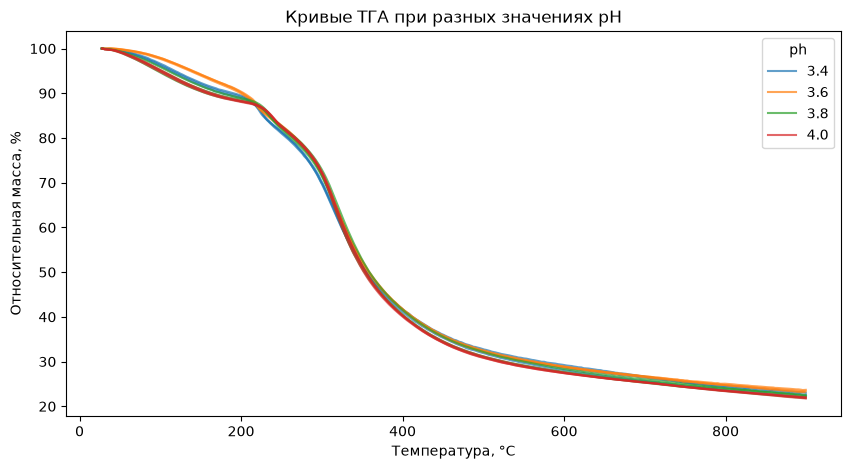

In [ ]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=df,
    x="temperature_C",
    y="mass_percent",
    hue="ph",
    units="sample_id",
    estimator=None,
    palette="tab10",
    alpha=0.7
)

plt.xlabel("Температура, °C")
plt.ylabel("Относительная масса, %")
plt.title("Кривые ТГА при разных значениях pH")
plt.show()

**Вывод:** Все исследованные образцы характеризуются сходной формой кривых ТГА. Основная потеря массы наблюдается приблизительно в области 250–400 °C, после чего скорость изменения массы уменьшается.

Кривые повторных измерений в целом близки друг к другу, однако между отдельными образцами заметны небольшие различия. Для более подробного сравнения рассмотрим область основной потери массы отдельно.

### 10.2. Сравнение кривых ТГА в области 250–400 °C

В области 250–400 °C наблюдается наиболее интенсивное изменение относительной массы. Рассмотрим этот участок подробнее, чтобы оценить различия между кривыми при разных значениях pH.

Для сравнения сохраним все повторные измерения без усреднения.

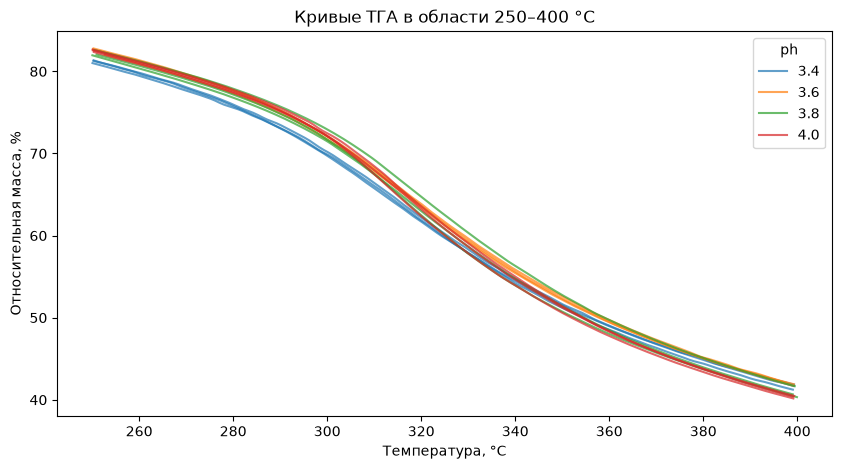

In [ ]:
region = df[
    (df["temperature_C"] >= 250) &
    (df["temperature_C"] <= 400)
]

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=region,
    x="temperature_C",
    y="mass_percent",
    hue="ph",
    units="sample_id",
    estimator=None,
    palette="tab10",
    alpha=0.7
)

plt.xlabel("Температура, °C")
plt.ylabel("Относительная масса, %")
plt.title("Кривые ТГА в области 250–400 °C")
plt.show()

**Вывод:** В области 250–400 °C различия между кривыми ТГА становятся более заметными. При температурах около 280–310 °C образцы, полученные при pH 3,4, в целом характеризуются несколько меньшей относительной массой по сравнению с остальными.

При дальнейшем нагревании кривые сближаются и частично пересекаются. Различия между образцами относительно невелики, поэтому по данным ТГА нельзя однозначно выделить pH 3,6 как условие максимальной термической стабильности.

Для более подробного сравнения положения и интенсивности основной стадии потери массы далее рассмотрим кривые ДТГ.

## 11. Анализ кривых ДТГ

Кривые ДТГ отражают скорость изменения относительной массы образца при нагревании.

Для сравнения повторных измерений построим отдельные графики для каждого значения pH. Это позволит оценить положение основного минимума ДТГ, его глубину и воспроизводимость экспериментальных кривых.

Каждое повторное измерение отображается отдельно, без усреднения.

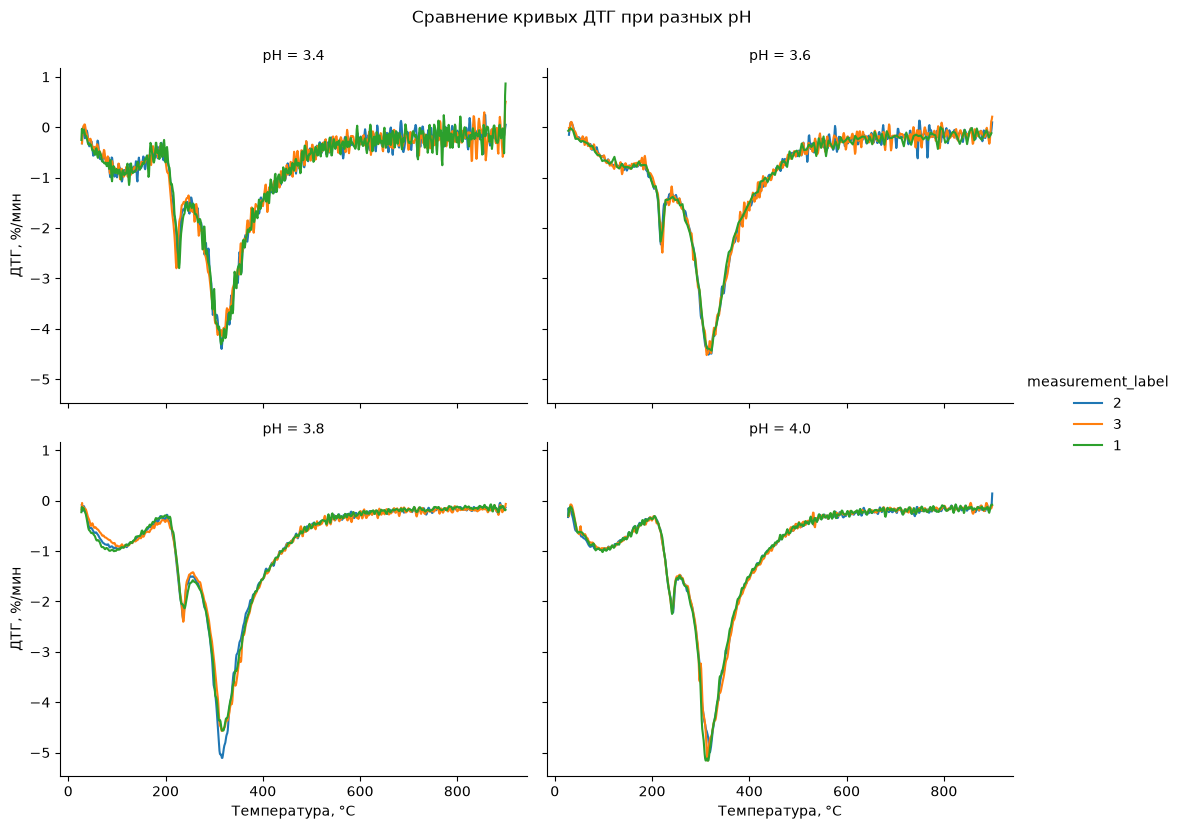

In [ ]:
plot_df = df[
    ["temperature_C", "dtg_pct_per_min", "ph", "measurement_number"]
].copy()

plot_df["measurement_label"] = plot_df["measurement_number"].astype(str)

g = sns.relplot(
    data=plot_df,
    x="temperature_C",
    y="dtg_pct_per_min",
    col="ph",
    col_wrap=2,
    hue="measurement_label",
    palette="tab10",
    kind="line",
    estimator=None,
    height=4,
    aspect=1.3
)

g.set_axis_labels("Температура, °C", "ДТГ, %/мин")
g.set_titles("pH = {col_name}")
g.figure.suptitle("Сравнение кривых ДТГ при разных pH", y=1.03);

**Вывод:** Кривые ДТГ при всех исследованных значениях pH имеют сходную форму. Наиболее интенсивное изменение массы наблюдается приблизительно в области 300–330 °C. Повторные измерения в целом хорошо согласуются, однако глубина основного минимума немного различается, особенно при pH 3,8.

При высоких температурах наблюдаются колебания сигнала, наиболее заметные при pH 3,4. Эти особенности не являются достаточным основанием для исключения отдельных точек и требуют учёта при дальнейшем анализе экспериментальных данных.

### 11.1. Положение основного минимума ДТГ

Для каждого измерения определим температуру и значение основного минимума ДТГ в диапазоне 250–400 °C.

Этот диапазон выбран по результатам визуального анализа как область основной потери массы. Полученные значения позволят сравнить положение наиболее интенсивной стадии потери массы между измерениями.

In [ ]:
dtg_region = df[
    (df["temperature_C"] >= 250) &
    (df["temperature_C"] <= 400)
]

min_indices = dtg_region.groupby(
    "sample_id"
)["dtg_pct_per_min"].idxmin()

dtg_peaks = df.loc[
    min_indices,
    ["sample_id", "ph", "temperature_C", "dtg_pct_per_min"]
].sort_values(["ph", "sample_id"])

dtg_peaks

,sample_id,ph,temperature_C,dtg_pct_per_min
2031,pH_3.4_30_70_m1,3.4,314.065,-4.30825
287,pH_3.4_30_70_m2,3.4,315.255,-4.39957
1161,pH_3.4_30_70_m3,3.4,317.314,-4.15079
4418,pH_3.6_30_70_m1,3.6,322.668,-4.43256
2904,pH_3.6_30_70_m2,3.6,316.179,-4.51376
3771,pH_3.6_30_70_m3,3.6,312.277,-4.52287
5696,pH_3.8_30_70_m1,3.8,317.044,-4.56336
4822,pH_3.8_30_70_m2,3.8,315.929,-5.10648
6567,pH_3.8_30_70_m3,3.8,315.470,-4.57174
7439,pH_4.0_30_70_m1,4.0,315.165,-5.16248


In [ ]:
dtg_summary = dtg_peaks.groupby("ph").agg(
    mean_peak_temp=("temperature_C", "mean"),
    std_peak_temp=("temperature_C", "std"),
    mean_min_dtg=("dtg_pct_per_min", "mean"),
    std_min_dtg=("dtg_pct_per_min", "std")
)

dtg_summary.round(2)


,mean_peak_temp,std_peak_temp,mean_min_dtg,std_min_dtg
ph,,,,
3.4,315.54,1.64,-4.29,0.13
3.6,317.04,5.25,-4.49,0.05
3.8,316.15,0.81,-4.75,0.31
4.0,315.87,2.23,-5.11,0.09


**Вывод:** Средняя температура основного минимума ДТГ для всех исследованных значений pH находится в диапазоне 315,54–317,04 °C. Различия между группами относительно невелики. Наибольшая средняя температура наблюдается при pH 3,6, однако для этой группы также характерен наибольший разброс значений (стандартное отклонение 5,25 °C). Дополнительно необходимо учитывать, что одно измерение при pH 3,6 выполнено с температурным шагом 5 °C.

Средняя величина минимума ДТГ изменяется от −4,29 %/мин при pH 3,4 до −5,11 %/мин при pH 4,0. Это указывает на различия в максимальной скорости потери массы, но само по себе не позволяет сделать вывод о сравнительной термической стабильности образцов.

Полученные данные не позволяют однозначно выделить pH 3,6 как условие максимальной термической стабильности. Оптимальные условия комплексообразования, определённые ранее, не обязательно соответствуют максимальной устойчивости к термическому разложению.

**Решение для дальнейшей обработки:** сохранить исходные кривые ДТГ и учитывать различия температурного шага при количественном сравнении измерений. Автоматическое сглаживание и интерполяция в рамках ETL не требуются.

## 12. Заключение

В ходе разведочного анализа исследован датасет термогравиметрического анализа гидрогелей на основе карбоксиметилагара и желатина, содержащий 9 768 строк и 18 столбцов.

### Качество и структура данных

В датасете представлены 12 измерений при четырёх значениях pH (3,4; 3,6; 3,8 и 4,0), по три повторных измерения для каждого значения. Пропуски и полностью дублирующиеся строки отсутствуют.

Проверка экспериментальных метаданных показала, что исходная масса навески постоянна внутри каждого измерения. Рассчитанная медианная скорость нагрева для всех измерений составляет 10 °C/мин и совпадает с заданным значением.

Обнаружено, что одно измерение при pH 3,6 выполнено с температурным шагом около 5 °C, тогда как остальные — с шагом около 1 °C. Эту особенность необходимо учитывать при дальнейшем сравнении термограмм.

### Особенности экспериментальных кривых

В исходных данных обнаружены 6 точек с относительной массой выше 100% и 108 точек с положительными значениями ДТГ. Эти значения требуют внимания, но без дополнительной проверки нет оснований считать их ошибочными.

Кривые ТГА и ДТГ имеют сходную форму при всех исследованных значениях pH. Основная потеря массы наблюдается приблизительно в области 250–400 °C.

Средняя температура основного минимума ДТГ находится в диапазоне 315,54–317,04 °C. Различия между группами относительно невелики, тогда как глубина минимумов изменяется заметнее.

По полученным данным нельзя однозначно выделить pH 3,6 как условие максимальной термической стабильности. Оптимальные условия комплексообразования и термическое поведение материалов характеризуют разные свойства системы.

### Решения для ETL

По результатам анализа принято решение:

1. Сохранить все 12 экспериментальных измерений без удаления отдельных точек.
2. Не выполнять автоматическое сглаживание, интерполяцию и удаление статистических выбросов.
3. Сохранить исходные значения температуры, относительной массы, ДТГ и экспериментальные метаданные.
4. Использовать преобразование типов данных и минимально необходимые проверки структуры и полноты.
5. Учитывать различия температурного шага при последующем количественном сравнении измерений.

Таким образом, датасет пригоден для дальнейшей обработки и хранения в PostgreSQL без дополнительной очистки экспериментальных кривых.